In [1]:
!pip install -q pandas numpy networkx python-louvain scikit-learn matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import community as community_louvain

In [5]:
from google.colab import files

uploaded = files.upload()

Saving ciao_trust_edgelist.csv to ciao_trust_edgelist.csv


In [6]:
filename = list(uploaded.keys())[0]

edges = pd.read_csv(filename)

print(edges.shape)
edges.head()

(111781, 2)


,Source,Target
0,1,2
1,1,3
2,1,4
3,1,5
4,1,6


In [8]:
G = nx.from_pandas_edgelist(
    edges,
    source="Source",
    target="Target",
    create_using=nx.DiGraph()
)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 7317
Number of edges: 111781


In [9]:
activity = pd.Series(
    dict(G.out_degree()),
    name="activity"
)

activity.head()

,activity
1,69
2,5
3,27
4,94
5,40


In [10]:
popularity = pd.Series(
    dict(G.in_degree()),
    name="popularity"
)

popularity.head()

,popularity
1,81
2,24
3,19
4,84
5,55


In [11]:
pagerank = pd.Series(
    nx.pagerank(G),
    name="pagerank"
)

pagerank.head()

,pagerank
1,0.000754
2,0.000133
3,0.000266
4,0.000480
5,0.000375


In [12]:
betweenness = pd.Series(
    nx.betweenness_centrality(G),
    name="betweenness"
)

betweenness.head()

,betweenness
1,0.003073
2,0.000004
3,0.000348
4,0.002368
5,0.000846


In [14]:
!pip uninstall -y community
!pip install -U python-louvain

Found existing installation: community 1.0.0b1
Uninstalling community-1.0.0b1:
  Successfully uninstalled community-1.0.0b1


In [15]:
import community.community_louvain as community_louvain

In [16]:
UG = G.to_undirected()

partition = community_louvain.best_partition(UG)

community_id = pd.Series(
    partition,
    name="community"
)

In [18]:
edge_set = set(
    zip(edges["Source"], edges["Target"])
)

out_edges = {}

for u, v in zip(edges["Source"], edges["Target"]):
    out_edges.setdefault(u, []).append(v)

def calculate_reciprocity(user):
    outgoing = out_edges.get(user, [])

    if len(outgoing) == 0:
        return 0

    mutual = sum(
        1 for target in outgoing
        if (target, user) in edge_set
    )

    return mutual / len(outgoing)

reciprocity = pd.Series(
    {
        user: calculate_reciprocity(user)
        for user in G.nodes()
    },
    name="reciprocity"
)

reciprocity.head()

,reciprocity
1,0.318841
2,0.800000
3,0.370370
4,0.489362
5,0.700000


In [19]:
trust_received = popularity.rename(
    "trust_received"
)

trust_received.head()

,trust_received
1,81
2,24
3,19
4,84
5,55


In [20]:
ciao_features = pd.concat(
    [
        activity,
        popularity,
        pagerank,
        betweenness,
        community_id,
        reciprocity,
        trust_received
    ],
    axis=1
)

ciao_features.index.name = "userID"

ciao_features = ciao_features.fillna(0)

print("Feature table shape:", ciao_features.shape)

ciao_features.head(10)

Feature table shape: (7317, 7)


,activity,popularity,pagerank,betweenness,community,reciprocity,trust_received
userID,,,,,,,
1,69,81,0.000754,0.003073,0,0.318841,81
2,5,24,0.000133,0.000004,0,0.800000,24
3,27,19,0.000266,0.000348,0,0.370370,19
4,94,84,0.000480,0.002368,0,0.489362,84
5,40,55,0.000375,0.000846,0,0.700000,55
6,14,73,0.000521,0.000481,0,0.928571,73
7,11,32,0.000273,0.000142,0,0.545455,32
8,78,100,0.000486,0.000878,0,0.769231,100
9,60,37,0.000230,0.000650,0,0.316667,37


In [21]:
ciao_features.to_csv(
    "ciao_behavior_features.csv"
)

print("Saved ciao_behavior_features.csv")

Saved ciao_behavior_features.csv


In [22]:
files.download("ciao_behavior_features.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
positive_edges = set(
    zip(edges["Source"], edges["Target"])
)

nodes = list(G.nodes())

negative_edges = []

np.random.seed(42)

while len(negative_edges) < len(positive_edges):

    source = np.random.choice(nodes)
    target = np.random.choice(nodes)

    if source == target:
        continue

    if (source, target) not in positive_edges:
        negative_edges.append((source, target))

negative_edges = list(set(negative_edges))

negative_edges = negative_edges[:len(positive_edges)]

print("Positive:", len(positive_edges))
print("Negative:", len(negative_edges))

Positive: 111781
Negative: 111663


In [25]:
def pair_features(source, target):

    source_neighbors = set(G.successors(source))
    target_neighbors = set(G.successors(target))

    common = len(
        source_neighbors.intersection(target_neighbors)
    )

    union = len(
        source_neighbors.union(target_neighbors)
    )

    jaccard = common / union if union > 0 else 0

    preferential_attachment = (
        G.out_degree(source) *
        G.out_degree(target)
    )

    same_community = int(
        partition.get(source) ==
        partition.get(target)
    )

    return [
        G.out_degree(source),
        G.in_degree(source),

        G.out_degree(target),
        G.in_degree(target),

        pagerank.get(source, 0),
        pagerank.get(target, 0),

        betweenness.get(source, 0),
        betweenness.get(target, 0),

        common,
        jaccard,

        preferential_attachment,

        same_community
    ]

In [26]:
feature_rows = []
labels = []

for source, target in positive_edges:

    feature_rows.append(
        pair_features(source, target)
    )

    labels.append(1)


for source, target in negative_edges:

    feature_rows.append(
        pair_features(source, target)
    )

    labels.append(0)

In [27]:
feature_names = [
    "source_out_degree",
    "source_in_degree",

    "target_out_degree",
    "target_in_degree",

    "source_pagerank",
    "target_pagerank",

    "source_betweenness",
    "target_betweenness",

    "common_neighbors",
    "jaccard",

    "preferential_attachment",

    "same_community"
]

X = pd.DataFrame(
    feature_rows,
    columns=feature_names
)

y = pd.Series(labels, name="trust")

print(X.shape)
X.head()

(223444, 12)


,source_out_degree,source_in_degree,target_out_degree,target_in_degree,source_pagerank,target_pagerank,source_betweenness,target_betweenness,common_neighbors,jaccard,preferential_attachment,same_community
0,53,22,45,100,0.000116,0.000483,0.000355,0.000396,14,0.166667,2385,1
1,11,8,14,73,0.000050,0.000521,0.000003,0.000481,0,0.000000,154,1
2,5,5,3,14,0.000182,0.000287,0.000337,0.000201,0,0.000000,15,1
3,510,46,5,12,0.000113,0.000069,0.016057,0.000154,2,0.003899,2550,1
4,510,96,3,11,0.000444,0.000107,0.016983,0.000086,0,0.000000,1530,0


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [29]:
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42)

In [30]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

print("F1 Score:",
      f1_score(y_test, y_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

Accuracy: 0.9177873749692318
Precision: 0.9188038020086083
Recall: 0.9166666666666666
F1 Score: 0.9177339901477832
ROC-AUC: 0.972675923684683


In [31]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.92      0.92      0.92     22333
           1       0.92      0.92      0.92     22356

    accuracy                           0.92     44689
   macro avg       0.92      0.92      0.92     44689
weighted avg       0.92      0.92      0.92     44689



In [32]:
importance = pd.DataFrame({
    "feature": feature_names,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

importance

,feature,importance
9,jaccard,0.158521
8,common_neighbors,0.155661
10,preferential_attachment,0.127303
11,same_community,0.108946
0,source_out_degree,0.104666
6,source_betweenness,0.067372
1,source_in_degree,0.066084
5,target_pagerank,0.052230
3,target_in_degree,0.049524
7,target_betweenness,0.040592


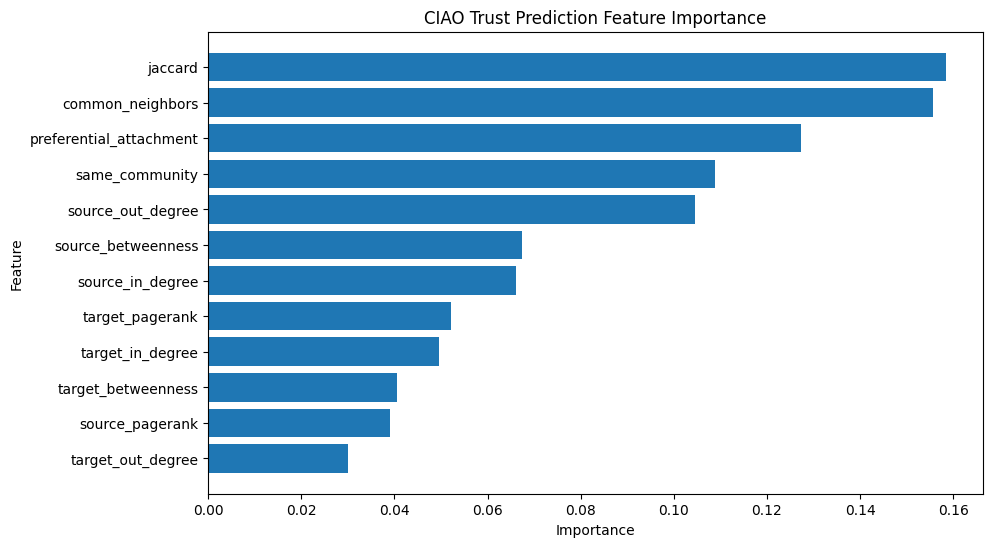

In [33]:
plt.figure(figsize=(10,6))

plt.barh(
    importance["feature"],
    importance["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("CIAO Trust Prediction Feature Importance")

plt.gca().invert_yaxis()

plt.show()

In [34]:
source_user = nodes[0]
target_user = nodes[1]

features = pd.DataFrame(
    [pair_features(source_user, target_user)],
    columns=feature_names
)

trust_probability = model.predict_proba(
    features
)[0][1]

print(
    f"Trust Score ({source_user} → {target_user}): "
    f"{trust_probability:.4f}"
)

Trust Score (1 → 2): 0.9633
